In [1]:
import os
import pickle

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GroupShuffleSplit, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.feature_selection import mutual_info_regression
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score
import xgboost as xgb
from xgboost import XGBRegressor

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 100)
os.makedirs("images", exist_ok=True)

## 1. Data preparation

Pitfalls handled when reading the file:
- The separator is `;` and the first column carries a BOM, so we read with `utf-8-sig`.
- `codprovf` / `codcantf` are read as **strings** to keep leading zeros (`"09"`, `"0901"`).
- `nucucal` and `nudocal` have blank cells for non-residential buildings. `isna()` does not see them because they are whitespace strings, so we convert them to real `NaN` ("not applicable").

In [2]:
df = pd.read_csv("data/6__2025_ESED_BDD.csv", sep=";", encoding="utf-8-sig",
                 dtype={"codprovf": str, "codcantf": str})
df.columns = df.columns.str.lower()

print("raw shape:", df.shape)
print("hidden nulls (isna):", int(df.isna().sum().sum()))
print("\nctipobr counts (1 = new, 2 = extension, 3 = reconstruction):")
print(df.ctipobr.value_counts().sort_index().to_dict())
print("cosm2 == 0 by ctipobr:", df[df.cosm2 == 0].ctipobr.value_counts().to_dict())

raw shape: (23334, 50)
hidden nulls (isna): 0

ctipobr counts (1 = new, 2 = extension, 3 = reconstruction):
{1: 19939, 2: 2459, 3: 936}
cosm2 == 0 by ctipobr: {3: 936}


Every `cosm2 = 0` row is a reconstruction (`ctipobr = 3`): the cost per m2 is simply not recorded for that type of work. We drop those rows and say so in the problem description.

In [3]:
df = df[df.ctipobr != 3].reset_index(drop=True)

for col in ["nucucal", "nudocal"]:
    blanks = (df[col].astype(str).str.strip() == "").sum()
    df[col] = pd.to_numeric(df[col].astype(str).str.strip().replace("", np.nan))
    print(f"{col}: {blanks} blank cells -> NaN")

print("\nshape after filter:", df.shape)
print(df.ctipobr.value_counts().sort_index().to_dict())

nucucal: 2201 blank cells -> NaN
nudocal: 2201 blank cells -> NaN

shape after filter: (22398, 50)
{1: 19939, 2: 2459}


## 2. Setting up the validation framework

In [4]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

df_full_train = df_full_train.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
print("train / val / test:", len(df_train), len(df_val), len(df_test))

eda = df_full_train.copy()

train / val / test: 13438 4480 4480


## 3. Exploratory data analysis

### 3.1 Structure

In [5]:
print("constant columns:", [c for c in eda.columns if eda[c].nunique() == 1])
print("provinces:", eda.codprovf.nunique(), "| cantons:", eda.codcantf.nunique())
print("canton code starts with its province code:", bool((eda.codcantf.str[:2] == eda.codprovf).all()))

cantons = eda.codcantf.value_counts()
print("cantons with < 30 rows:", int((cantons < 30).sum()), "| with < 10 rows:", int((cantons < 10).sum()))
print("\nrows per province (top 4, % of data):")
print((eda.codprovf.value_counts(normalize=True).head(4) * 100).round(1).to_dict())

constant columns: ['anio']
provinces: 24 | cantons: 217
canton code starts with its province code: True
cantons with < 30 rows: 110 | with < 10 rows: 57

rows per province (top 4, % of data):
{'09': 27.1, '17': 9.6, '23': 6.2, '18': 6.2}


`anio` is constant (everything is 2025). Provinces and cantons are nested, and many cantons have very few rows
### 3.2 The target: `cosm2`

In [6]:
y = eda.cosm2
print(y.describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1).to_string())
print("\nskew raw:", round(y.skew(), 2), "| skew of log1p:", round(np.log1p(y).skew(), 2))

vc = y.value_counts()
top = vc.head(10).rename("n").to_frame()
top["pct"] = (100 * top.n / len(y)).round(1)
print("\nmost frequent values:")
print(top.T.to_string())
print("\ndistinct values:", y.nunique())
print("share covered by the 7 most frequent values: %.1f%%" % (100 * vc.head(7).sum() / len(y)))
print("share that is a multiple of 50: %.1f%%" % (100 * (y % 50 == 0).mean()))

count    17918.0
mean       425.9
std        216.7
min         40.0
1%          85.0
5%         199.0
25%        300.0
50%        385.0
75%        480.0
95%        948.0
99%       1158.0
max       1500.0

skew raw: 1.81 | skew of log1p: -0.36

most frequent values:
cosm2     300     350     400     415     450    480    500    360    250    200
n      1997.0  1711.0  1240.0  1079.0  1057.0  870.0  630.0  618.0  595.0  525.0
pct      11.1     9.5     6.9     6.0     5.9    4.9    3.5    3.4    3.3    2.9

distinct values: 765
share covered by the 7 most frequent values: 47.9%
share that is a multiple of 50: 50.8%


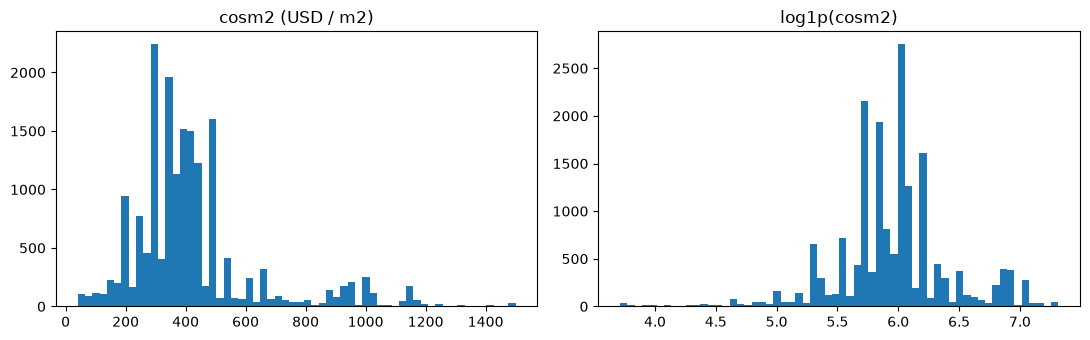

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(y, bins=60)
ax[0].set_title("cosm2 (USD / m2)")
ax[1].hist(np.log1p(y), bins=60)
ax[1].set_title("log1p(cosm2)")
plt.tight_layout()
plt.savefig("images/eda_target.png", dpi=120)
plt.show()

The raw target is right-skewed and the log is close to symmetric, so we model `log1p(cosm2)`. The histogram hides the spikes at round numbers, which is why the frequency table above matters.

In [8]:
print("quantiles:", y.quantile([.001, .005, .01, .02, .03, .5, .97, .99, .999]).round(0).to_dict())
low = eda[eda.cosm2 <= 50]
print("\nrows with cosm2 <= 50:", len(low), "(%.2f%%)" % (100 * len(low) / len(eda)))
print("values:", low.cosm2.value_counts().to_dict())
print("top provinces among them:", low.codprovf.value_counts().head(3).to_dict())
print("\nrows with cosm2 >= 1000:", int((y >= 1000).sum()), "| max:", y.max())

quantiles: {0.001: 40.0, 0.005: 60.0, 0.01: 85.0, 0.02: 125.0, 0.03: 150.0, 0.5: 385.0, 0.97: 1012.0, 0.99: 1158.0, 0.999: 1500.0}

rows with cosm2 <= 50: 66 (0.37%)
values: {40: 34, 50: 9, 43: 4, 45: 4, 42: 3, 44: 3, 47: 3, 49: 2, 41: 2, 48: 1, 46: 1}
top provinces among them: {'09': 22, '13': 15, '12': 8}

rows with cosm2 >= 1000: 784 | max: 1500


**Repeated values and the canton effect.** Hypothesis: the spike at 415 comes from specific municipalities that apply a fixed value.

In [9]:
v415 = eda[eda.cosm2 == 415]
share = v415.codcantf.value_counts(normalize=True)
print("rows with 415:", len(v415), "| cantons involved:", v415.codcantf.nunique())
print("share of all 415s by canton:", share.head(3).round(3).to_dict())

top_canton = share.index[0]
c = eda[eda.codcantf == top_canton]
trio = ["espverd", "tocup", "cintern"]
print(f"\ncanton {top_canton}: {len(c)} rows | all cosm2 == 415: {(c.cosm2 == 415).all()} "
      f"| espverd, tocup, cintern all 0: {(c[trio] == 0).all(axis=1).all()}")
print("(check which canton this is in the DPA 2025 classifier)")

zeros = eda[(eda[trio] == 0).all(axis=1)]
print(f"\nrows with {trio} all 0: {len(zeros)} | % that are 415: {100 * (zeros.cosm2 == 415).mean():.1f}"
      f" | cantons: {zeros.codcantf.nunique()} | share from the top canton: {zeros.codcantf.value_counts(normalize=True).iloc[0]:.2f}")

rows with 415: 1079 | cantons involved: 11
share of all 415s by canton: {'1701': 0.991, '1705': 0.001, '1101': 0.001}

canton 1701: 1069 rows | all cosm2 == 415: True | espverd, tocup, cintern all 0: True
(check which canton this is in the DPA 2025 classifier)

rows with ['espverd', 'tocup', 'cintern'] all 0: 1129 | % that are 415: 94.7 | cantons: 28 | share from the top canton: 0.95


In [10]:
by_canton = eda.groupby("codcantf").cosm2.agg(
    n="size",
    dominant=lambda s: s.value_counts().index[0],
    dominant_share=lambda s: s.value_counts(normalize=True).iloc[0],
)
big = by_canton[by_canton.n >= 30]
print("cantons with >= 30 rows:", len(big))
print("median share of the dominant value inside a canton: %.2f" % big.dominant_share.median())
print("cantons with >= 50%% in one value: %d | >= 80%%: %d" % ((big.dominant_share >= .5).sum(), (big.dominant_share >= .8).sum()))
print("dominant values across cantons:", big.dominant.value_counts().head(8).to_dict())

cantons with >= 30 rows: 107
median share of the dominant value inside a canton: 0.26
cantons with >= 50% in one value: 11 | >= 80%: 4
dominant values across cantons: {300: 34, 350: 28, 400: 14, 200: 5, 450: 3, 250: 2, 280: 2, 180: 1}


What this says:
- 415 is not a "typical cost": it comes from **one canton that reports the same value for every permit** (and leaves three other columns at 0).
- The other repeated values (300, 350, 400) are the dominant value in many cantons, so they are shared round numbers, not a single municipality's rule.
- If we drop the canton, the three zero columns act as a **proxy** for it. That is a legitimate signal in this dataset, but it says more about how municipalities report than about construction costs.

### 3.3 Duplicated rows

In [11]:
key_cols = [c for c in eda.columns if c != "id"]
dup = eda.duplicated(subset=key_cols, keep=False)
groups = eda[dup].groupby(key_cols, dropna=False).size()

print("rows inside duplicate groups: %d (%.1f%%)" % (dup.sum(), 100 * dup.mean()))
print("groups:", len(groups), "| group size min/median/max:", groups.min(), groups.median(), groups.max())
print("\ntop cantons among duplicates:", eda[dup].codcantf.value_counts().head(5).to_dict())
print("ctipobr among duplicates:", eda[dup].ctipobr.value_counts(normalize=True).round(2).to_dict())
print("cdispuso among duplicates:", eda[dup].cdispuso.value_counts(normalize=True).round(2).head(3).to_dict())
print("median cosm2 duplicates vs rest:", eda[dup].cosm2.median(), eda[~dup].cosm2.median())

make_key = lambda d: pd.util.hash_pandas_object(d[key_cols], index=False)
twin_rate = make_key(df_val).isin(set(make_key(df_train))).mean()
print("\nvalidation rows with an exact twin in train: %.1f%%" % (100 * twin_rate))

rows inside duplicate groups: 2507 (14.0%)
groups: 541 | group size min/median/max: 2 3.0 36

top cantons among duplicates: {'0901': 1431, '0906': 717, '2301': 161, '0701': 32, '1308': 30}
ctipobr among duplicates: {1: 1.0}
cdispuso among duplicates: {1: 1.0, 4: 0.0, 2: 0.0}
median cosm2 duplicates vs rest: 550.0 360.0

validation rows with an exact twin in train: 13.9%


Duplicates are concentrated in a few cantons and are almost all new single-dwelling buildings. They may be real (housing developments with several identical permits). If twins end up on both sides of a split, validation scores can be optimistic.

### 3.4 Numeric features

`carco` is derived (`cares + carnres + cardpar`) and `cvae` almost reproduces the target when divided by `carco`, so neither is used as a feature.

In [12]:
num_cols = ["cares", "carnres", "csute", "caesv", "carpat", "nupical", "cperm", "cnuvical", "nucucal", "nudocal"]
log_y = np.log1p(eda.cosm2)

summary = pd.DataFrame({
    "pct_empty": eda[num_cols].isna().mean() * 100,
    "pct_zero": (eda[num_cols] == 0).mean() * 100,
    "median": eda[num_cols].median(),
    "p99": eda[num_cols].quantile(.99),
    "max": eda[num_cols].max(),
    "skew": eda[num_cols].skew(),
    "spearman_vs_target": eda[num_cols].corrwith(log_y, method="spearman"),
}).round(2)
print(summary.to_string())

corr = eda[num_cols].corr(method="spearman")
pairs = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.index)
         for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) >= 0.7]
print("\nhighly correlated pairs (|spearman| >= 0.7):", pairs)
print("cardpar non-zero rows:", int((eda.cardpar != 0).sum()))

          pct_empty  pct_zero  median      p99      max   skew  spearman_vs_target
cares          0.00      9.71   120.0  1717.94  22836.0  16.43               -0.02
carnres        0.00     87.21     0.0  1616.66  47201.0  30.59               -0.14
csute          0.00     10.21   212.0  7846.39  30000.0   7.27               -0.17
caesv          0.00     13.72   100.0  4950.00  14897.0   6.55               -0.08
carpat         0.00     76.27     0.0   885.83  15000.0  20.94               -0.10
nupical        0.00      0.00     2.0     6.00     32.0   7.54                0.18
cperm          0.00      0.00     1.0    10.00     83.0  16.47                0.05
cnuvical       0.00      9.71     1.0    15.00    249.0  22.02                0.05
nucucal        9.71      0.00     8.0    12.00     30.0   0.01                0.09
nudocal        9.71      0.00     3.0     5.00     11.0   0.34                0.06

highly correlated pairs (|spearman| >= 0.7): [('cares', 'cnuvical', np.float64(0.7)), 

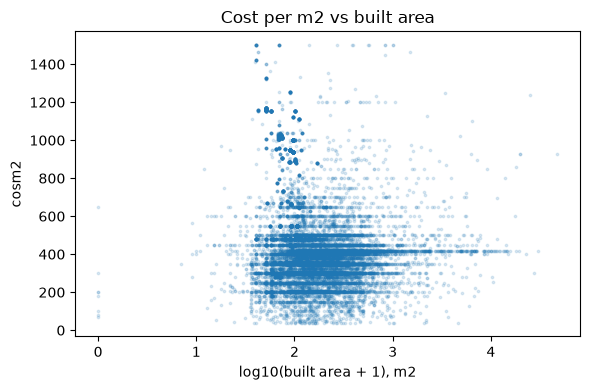

In [13]:
area = eda.cares + eda.carnres
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(np.log10(area + 1), eda.cosm2, s=3, alpha=0.15)
ax.set_xlabel("log10(built area + 1), m2")
ax.set_ylabel("cosm2")
ax.set_title("Cost per m2 vs built area")
plt.tight_layout()
plt.savefig("images/eda_area.png", dpi=120)
plt.show()

Areas are extremely skewed and only weakly correlated with the target, so a linear model will have little to work with. Several columns are redundant with each other (`csute`/`caesv`, `nucucal`/`nudocal`).

The data dictionary lists ranges that do not always match the file (for example, a maximum of 11,200 for `csute` while the data goes higher), so do not rely on them for validation.

### 3.5 Categorical features

Many columns are numeric codes but are really categories. A `0` usually means "not applicable", but in `tocup` and `fideic` it means "no response".

In [14]:
cat_cols = ["codreg", "careaur", "propie", "cimi", "piso", "estru", "entrepisos", "pared", "cubi",
            "ctipobr", "cores", "coams", "cdispuso", "cdisprfi", "secredit", "espverd", "asagua",
            "asluz", "asalcant", "cintern", "astelf", "aedif", "tocup", "fideic", "casaedif",
            "tipfinan", "valterr", "mes"]

rows = []
for col in cat_cols:
    freq = eda[col].value_counts(normalize=True)
    med = eda.groupby(col).cosm2.median()
    rows.append({"col": col, "n_categories": len(freq), "pct_top_category": round(100 * freq.iloc[0], 1),
                 "n_categories_under_1pct": int((freq < .01).sum()),
                 "median_min": int(med.min()), "median_max": int(med.max())})
print(pd.DataFrame(rows).to_string(index=False))

       col  n_categories  pct_top_category  n_categories_under_1pct  median_min  median_max
    codreg             4              47.8                        1         300         500
   careaur             2              85.9                        0         380         400
    propie             2              99.7                        1         310         387
      cimi             6              81.2                        2         280         415
      piso            10              39.1                        3         300         450
     estru             5              80.9                        1         350         550
entrepisos             5              75.6                        1         350         415
     pared            10              56.8                        4         300         938
      cubi             9              34.5                        2         300         480
   ctipobr             2              89.2                        0         350 

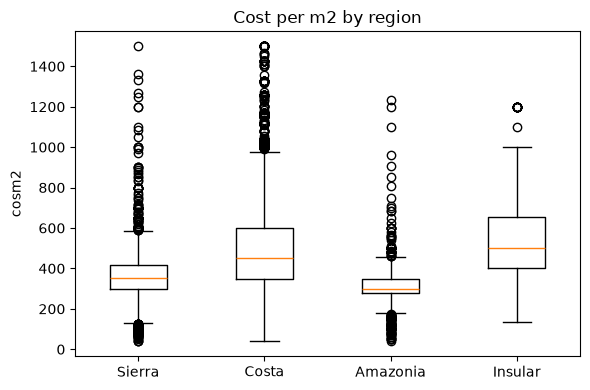

          size  median
ctipobr               
1        15974   400.0
2         1944   350.0
           size  median
cdispuso               
1         12661   400.0
2          1567   390.0
3          1396   400.0
4          1313   320.0
5           161   300.0
6            16   330.5
7            40   383.0
8             7   367.0
9            29   324.0
10           36   418.5
11            4   333.0
13          554   400.0
14          134   200.0

provinces, lowest and highest median:
          size  median
codprovf              
08         132   250.0
04         286   299.0
05         518   300.0
17        1715   415.0
09        4853   480.0
20          95   500.0


In [15]:
region_names = {1: "Sierra", 2: "Costa", 3: "Amazonia", 4: "Insular"}
regions = sorted(eda.codreg.unique())
fig, ax = plt.subplots(figsize=(6, 4))
ax.boxplot([eda[eda.codreg == r].cosm2 for r in regions])
ax.set_xticklabels([region_names.get(r, r) for r in regions])
ax.set_ylabel("cosm2")
ax.set_title("Cost per m2 by region")
plt.tight_layout()
plt.savefig("images/eda_region.png", dpi=120)
plt.show()

print(eda.groupby("ctipobr").cosm2.agg(["size", "median"]).to_string())
print(eda.groupby("cdispuso").cosm2.agg(["size", "median"]).to_string())
prov = eda.groupby("codprovf").cosm2.agg(["size", "median"]).sort_values("median")
print("\nprovinces, lowest and highest median:")
print(pd.concat([prov.head(3), prov.tail(3)]).to_string())

Caveats:
- Several columns are nearly constant (`propie`, `asluz`, `asagua`, `secredit`) and carry little information.
- Differences in the median by category (for example by `estru` or `cubi`) can be a location effect in disguise, because a few cantons dominate the data. Do not read them as causal.
- Province `09` alone is about a quarter of the rows.



## 4. Feature importance

Mutual information with `log1p(cosm2)`, on the training set. To know what counts as signal, the same computation is repeated with a **shuffled** target.

Caveat: variables with many categories (`codcantf`) or continuous values tend to score higher by construction, so this is a rough ranking, not a selection.

In [16]:
exclude = ["id", "anio", "fper", "cvae", "carco", "cardpar", "cdispsut", "cdisparc", "cosm2"]
features_mi = [c for c in df_train.columns if c not in exclude]
Xmi = pd.DataFrame({c: (df_train[c].fillna(-1) if c in num_cols else df_train[c].astype("category").cat.codes)
                    for c in features_mi})
is_discrete = [c not in num_cols for c in features_mi]
y_mi = np.log1p(df_train.cosm2)

mi = pd.Series(mutual_info_regression(Xmi, y_mi, discrete_features=is_discrete, random_state=1),
               index=features_mi).sort_values(ascending=False)
y_shuffled = y_mi.sample(frac=1, random_state=1).values
floor = pd.Series(mutual_info_regression(Xmi, y_shuffled, discrete_features=is_discrete, random_state=1),
                  index=features_mi).max()

print("noise floor (max MI with shuffled target): %.3f" % floor)
print(mi.round(3).to_string())

noise floor (max MI with shuffled target): 0.015
codcantf      1.152
codprovf      0.667
cares         0.617
csute         0.545
caesv         0.507
pared         0.443
piso          0.384
cdisprfi      0.378
tocup         0.351
nucucal       0.340
aedif         0.269
casaedif      0.253
codreg        0.249
cubi          0.235
nudocal       0.229
espverd       0.212
fideic        0.212
cimi          0.211
valterr       0.204
mes           0.201
estru         0.194
entrepisos    0.190
cintern       0.160
astelf        0.155
tipfinan      0.136
nupical       0.110
cdispuso      0.108
cperm         0.101
cores         0.100
cnuvical      0.097
secredit      0.071
carpat        0.070
nuvisec       0.066
careaur       0.058
asalcant      0.047
asagua        0.035
asluz         0.029
coams         0.028
carnres       0.024
ctipobr       0.023
propie        0.003


Features such as `mes`, `tocup`, `espverd` and `fideic` rank high, but that probably reflects how municipalities report (and the canton effect from section 3.2), not construction cost itself.

**Features used by the models.** Everything except: `id`, `anio` (constant), `fper` (same information as `mes`), `mes` (administrative), `propie`, `secredit` and `nuvisec` (near-constant), `cvae` (leaks the target), and `carco`, `cdispsut`, `cdisparc`, `cardpar` (derived or almost always zero). That leaves 27 categorical and 10 numerical columns.

## 5. Models

Two evaluation tools:
- **5-fold cross-validation** (`KFold(n_splits=5, shuffle=True, random_state=1)`) on train + validation (`df_full_train`). It tunes Ridge, the decision tree and XGBoost, and it compares all the models. Every fold fits its own `DictVectorizer`, so nothing from the validation fold leaks into training.
- **The validation split** (`df_val`), used where cross-validation would be too slow (the random forest has many more and much heavier fits) and for the sanity experiments.

 The target is `log1p(cosm2)`; the main metric is the RMSE on that scale, also reported in USD and as R2.

In [17]:
categorical = ["codreg", "codprovf", "codcantf", "careaur",
               "cimi", "piso", "estru", "entrepisos", "pared", "cubi",
               "ctipobr", "cores", "coams", "cdispuso", "cdisprfi",
               "espverd", "asagua", "asluz", "asalcant", "cintern", "astelf", "aedif",
               "tocup", "fideic", "casaedif", "tipfinan", "valterr"]
numerical = ["cares", "carnres", "csute", "caesv", "carpat",
             "nupical", "cperm", "cnuvical", "nucucal", "nudocal"]

def to_dicts(d):
    d = d[categorical + numerical].copy()
    d[categorical] = d[categorical].astype(str)          
    d[["nucucal", "nudocal"]] = d[["nucucal", "nudocal"]].fillna(0)   # not applicable -> 0
    return d.to_dict(orient="records")


dv = DictVectorizer()
X_train = dv.fit_transform(to_dicts(df_train))
X_val = dv.transform(to_dicts(df_val))
y_train = np.log1p(df_train.cosm2.values)
y_val = np.log1p(df_val.cosm2.values)
print("matrix:", X_train.shape)

def evaluate(pred, y_true):
    """Both arguments on the log1p scale."""
    return {"RMSE_log1p": float(np.sqrt(np.mean((y_true - pred) ** 2))),
            "RMSE_usd": float(np.sqrt(np.mean((np.expm1(y_true) - np.expm1(pred)) ** 2))),
            "R2": float(r2_score(y_true, pred))}


full_dicts = to_dicts(df_full_train)
y_full = np.log1p(df_full_train.cosm2.values)
folds = list(KFold(n_splits=5, shuffle=True, random_state=1).split(full_dicts))
print("folds:", [len(va) for _, va in folds])

def cv_scores(make_model):

    rows = []
    for tr_idx, va_idx in folds:
        model = make_model()
        model.fit([full_dicts[i] for i in tr_idx], y_full[tr_idx])
        pred = model.predict([full_dicts[i] for i in va_idx])
        rows.append(evaluate(pred, y_full[va_idx]))
    return pd.DataFrame(rows)

def cv_summary(scores):
    return {"RMSE_log1p": float(scores.RMSE_log1p.mean()), "std": float(scores.RMSE_log1p.std()),
            "RMSE_usd": float(scores.RMSE_usd.mean()), "R2": float(scores.R2.mean())}

matrix: (13438, 399)
folds: [3584, 3584, 3584, 3583, 3583]


### 5.1 Baseline: median cost by canton

Location alone, with no machine learning. Any model should beat this.

In [18]:
def baseline_pred(train_part, test_part):
    prov = train_part.groupby("codprovf").cosm2.median()
    cant = train_part.groupby("codcantf").cosm2.median()
    return test_part.codcantf.map(cant).fillna(test_part.codprovf.map(prov)).fillna(train_part.cosm2.median())


print("validation split:", {k: round(v, 3) for k, v in evaluate(np.log1p(baseline_pred(df_train, df_val).values), y_val).items()})

rows = []
for tr_idx, va_idx in folds:
    pred = baseline_pred(df_full_train.iloc[tr_idx], df_full_train.iloc[va_idx])
    rows.append(evaluate(np.log1p(pred.values), y_full[va_idx]))
cv_results = {"canton median (baseline)": cv_summary(pd.DataFrame(rows))}
print("5-fold CV:", {k: round(v, 3) for k, v in cv_results["canton median (baseline)"].items()})

validation split: {'RMSE_log1p': 0.395, 'RMSE_usd': 179.274, 'R2': 0.322}
5-fold CV: {'RMSE_log1p': 0.394, 'std': 0.009, 'RMSE_usd': 176.76, 'R2': 0.31}


### 5.2 Linear model (Ridge)

One regularization parameter, tuned with cross-validation.

In [19]:
rows = []
for alpha in [0.01, 0.1, 1, 3, 10, 30, 100]:
    s = cv_summary(cv_scores(lambda: make_pipeline(DictVectorizer(), Ridge(alpha=alpha))))
    rows.append({"alpha": alpha, "RMSE_log1p": s["RMSE_log1p"], "std": s["std"]})
ridge_tbl = pd.DataFrame(rows)
print(ridge_tbl.round(4).to_string(index=False))

best_alpha = float(ridge_tbl.loc[ridge_tbl.RMSE_log1p.idxmin(), "alpha"])
print("best alpha:", best_alpha)

 alpha  RMSE_log1p    std
  0.01      0.3628 0.0103
  0.10      0.3627 0.0103
  1.00      0.3627 0.0103
  3.00      0.3632 0.0103
 10.00      0.3642 0.0102
 30.00      0.3672 0.0102
100.00      0.3731 0.0112
best alpha: 0.1


### 5.3 Decision tree

Tuned on `max_depth` and `min_samples_leaf` with cross-validation.

In [20]:
rows = []
for depth in [5, 8, 10, 15, 20]:
    for leaf in [1, 5, 10, 20]:
        s = cv_summary(cv_scores(lambda: make_pipeline(
            DictVectorizer(), DecisionTreeRegressor(max_depth=depth, min_samples_leaf=leaf, random_state=1))))
        rows.append({"max_depth": depth, "min_samples_leaf": leaf, "RMSE_log1p": s["RMSE_log1p"], "std": s["std"]})
tree_tbl = pd.DataFrame(rows).sort_values("RMSE_log1p")
print(tree_tbl.head(8).round(4).to_string(index=False))

best = tree_tbl.iloc[0]
best_tree = {"max_depth": int(best.max_depth), "min_samples_leaf": int(best.min_samples_leaf), "random_state": 1}
print("best:", best_tree)


 max_depth  min_samples_leaf  RMSE_log1p    std
        10                 5      0.3425 0.0168
        15                10      0.3426 0.0127
        10                10      0.3434 0.0133
        15                 5      0.3451 0.0180
        15                20      0.3469 0.0120
        10                20      0.3472 0.0141
        20                20      0.3485 0.0111
        20                10      0.3486 0.0136
best: {'max_depth': 10, 'min_samples_leaf': 5, 'random_state': 1}


### 5.4 Random forest

Cross-validating every step would take too long on a single core, so the forest is tuned on the validation split, one parameter at a time (each step keeps the best value of the previous ones): `max_depth`, `min_samples_leaf`, `max_features`, then the number of trees. It still goes through cross-validation in section 5.6.

In [21]:
def fit_rf(**params):
    cfg = dict(n_estimators=60, max_features=0.3, random_state=1, n_jobs=-1)
    cfg.update(params)
    m = RandomForestRegressor(**cfg).fit(X_train, y_train)
    return m, evaluate(m.predict(X_val), y_val)["RMSE_log1p"]

rf_best = {"max_depth": None, "min_samples_leaf": 1, "max_features": 0.3}
for name, grid in [("max_depth", [10, 15, 20]), ("min_samples_leaf", [1, 3, 5]),
                   ("max_features", [0.2, 0.3]), ("n_estimators", [60, 100, 200])]:
    scores = {}
    for v in grid:
        scores[v] = fit_rf(**{**rf_best, name: v})[1]
    rf_best[name] = min(scores, key=scores.get)
    print(name, {str(k): round(v, 4) for k, v in scores.items()}, "->", rf_best[name])

print(rf_best)

max_depth {'10': 0.3244, '15': 0.3114, '20': 0.3069} -> 20
min_samples_leaf {'1': 0.3069, '3': 0.3101, '5': 0.314} -> 1
max_features {'0.2': 0.3064, '0.3': 0.3069} -> 0.2
n_estimators {'60': 0.3064, '100': 0.306, '200': 0.3055} -> 200
{'max_depth': 20, 'min_samples_leaf': 1, 'max_features': 0.2, 'n_estimators': 200}


### 5.5 XGBoost

The tuning follows the usual order (`eta`, then `max_depth`, then `min_child_weight`), but each candidate is scored with **`xgb.cv`** (5 folds, the same folds as the other models) and early stopping, which also gives the number of trees.

In [22]:
feature_names = dv.get_feature_names_out().tolist()
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=feature_names)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=feature_names)

# For cross-validation: train + validation. The vectorizer only learns which codes exist (no target involved).
dv_full = DictVectorizer()
X_full = dv_full.fit_transform(full_dicts)
dfull = xgb.DMatrix(X_full, label=y_full, feature_names=dv_full.get_feature_names_out().tolist())

base_params = {"eta": 0.1, "max_depth": 6, "min_child_weight": 1,
               "objective": "reg:squarederror", "eval_metric": "rmse",
               "subsample": 0.8, "colsample_bytree": 0.8, "tree_method": "hist",
               "seed": 1, "verbosity": 1}

def run_cv(params):
    res = xgb.cv(params, dfull, num_boost_round=1000, folds=folds,
                 early_stopping_rounds=30, seed=1, verbose_eval=False)
    return float(res["test-rmse-mean"].iloc[-1]), float(res["test-rmse-std"].iloc[-1]), len(res)

xgb_params = dict(base_params)
for name, grid in [("eta", [0.05, 0.1, 0.2]), ("max_depth", [3, 4, 6, 8]),
                   ("min_child_weight", [1, 5, 10])]:
    scores = {}
    for v in grid:
        mean, std, rounds = run_cv({**xgb_params, name: v})
        scores[v] = (mean, rounds)
    xgb_params[name] = min(scores, key=lambda k: scores[k][0])
    print(name, {str(k): (round(v[0], 4), v[1]) for k, v in scores.items()}, "->", xgb_params[name])

cv_mean, cv_std, cv_rounds = run_cv(xgb_params)
print("\nchosen:", {k: xgb_params[k] for k in ["eta", "max_depth", "min_child_weight"]},
      "| trees:", cv_rounds, "| CV RMSE_log1p: %.4f (std %.4f)" % (cv_mean, cv_std))

eta {'0.05': (0.306, 930), '0.1': (0.308, 336), '0.2': (0.3104, 175)} -> 0.05
max_depth {'3': (0.3177, 1000), '4': (0.3111, 1000), '6': (0.306, 930), '8': (0.3046, 548)} -> 8
min_child_weight {'1': (0.3046, 548), '5': (0.3054, 509), '10': (0.3069, 362)} -> 1

chosen: {'eta': 0.05, 'max_depth': 8, 'min_child_weight': 1} | trees: 548 | CV RMSE_log1p: 0.3046 (std 0.0125)


      train     val
0    0.4608  0.4695
137  0.2533  0.3118
274  0.2267  0.3079
547  0.1889  0.3051


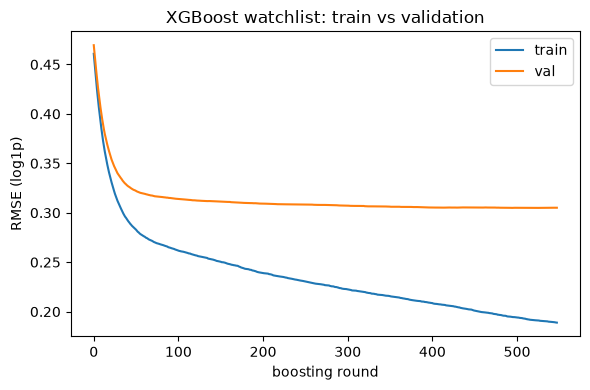

In [23]:
# Watchlist run
watchlist = [(dtrain, "train"), (dval, "val")]
evals_result = {}
booster = xgb.train(xgb_params, dtrain, num_boost_round=cv_rounds,
                    evals=watchlist, evals_result=evals_result, verbose_eval=False)
curve = pd.DataFrame({"train": evals_result["train"]["rmse"], "val": evals_result["val"]["rmse"]})
show = sorted({0, cv_rounds // 4, cv_rounds // 2, cv_rounds - 1})
print(curve.iloc[show].round(4).to_string())

fig, ax = plt.subplots(figsize=(6, 4))
curve.plot(ax=ax)
ax.set_xlabel("boosting round"); ax.set_ylabel("RMSE (log1p)")
ax.set_title("XGBoost watchlist: train vs validation")
plt.tight_layout()
plt.savefig("images/xgb_learning_curve.png", dpi=120)
plt.show()

In [24]:
# The deployed model is a scikit-learn pipeline, so the same parameters go into XGBRegressor.
# Check that both interfaces give the same predictions.
xgb_sk_params = dict(n_estimators=cv_rounds, learning_rate=xgb_params["eta"], max_depth=xgb_params["max_depth"],
                     min_child_weight=xgb_params["min_child_weight"], subsample=0.8, colsample_bytree=0.8,
                     tree_method="hist", random_state=1, n_jobs=-1)
xgb_model = XGBRegressor(**xgb_sk_params).fit(X_train, y_train)

print("max |XGBRegressor - xgb.train| on validation: %.2e" % np.abs(xgb_model.predict(X_val) - booster.predict(dval)).max())
xgb_val = evaluate(xgb_model.predict(X_val), y_val)
print("validation split:", {k: round(v, 3) for k, v in xgb_val.items()})

max |XGBRegressor - xgb.train| on validation: 0.00e+00
validation split: {'RMSE_log1p': 0.305, 'RMSE_usd': 109.331, 'R2': 0.596}


### 5.6 Comparison with cross-validation

Every tuned model is evaluated with the same 5 folds, as a pipeline `make_pipeline(DictVectorizer(), model)`. The `std` column is the standard deviation of the RMSE across folds: differences between models that are smaller than that should be read as ties.

In [25]:
cv_models = {
    "Ridge": lambda: make_pipeline(DictVectorizer(), Ridge(alpha=best_alpha)),
    "Decision tree": lambda: make_pipeline(DictVectorizer(), DecisionTreeRegressor(**best_tree)),
    "Random forest": lambda: make_pipeline(DictVectorizer(), RandomForestRegressor(random_state=1, n_jobs=-1, **rf_best)),
    "XGBoost": lambda: make_pipeline(DictVectorizer(), XGBRegressor(**xgb_sk_params)),
}
for name, make_model in cv_models.items():
    cv_results[name] = cv_summary(cv_scores(make_model))

cv_table = pd.DataFrame(cv_results).T.round(3).sort_values("RMSE_log1p")
print(cv_table.to_string())

                          RMSE_log1p    std  RMSE_usd     R2
XGBoost                        0.304  0.013   106.991  0.588
Random forest                  0.305  0.014   104.211  0.587
Decision tree                  0.342  0.017   124.788  0.478
Ridge                          0.363  0.010   158.668  0.414
canton median (baseline)       0.394  0.009   176.760  0.310


### 5.7 Feature importance and two sanity experiments

codcantf    0.383
codprovf    0.258
cdisprfi    0.056
pared       0.038
codreg      0.025
estru       0.025
tocup       0.025
cdispuso    0.023
piso        0.022
cubi        0.018
valterr     0.018
coams       0.017
fideic      0.010
casaedif    0.008
cimi        0.007


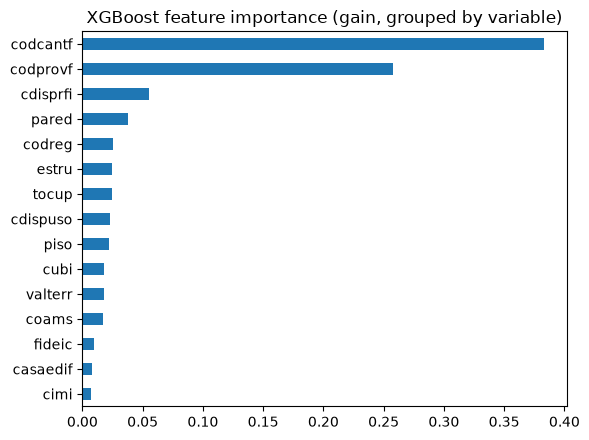

In [26]:
# Importance of the original features: sum the importance of all one-hot columns of the same variable
imp = pd.Series(xgb_model.feature_importances_, index=dv.feature_names_)
imp_by_feature = imp.groupby(lambda n: n.split("=")[0]).sum().sort_values(ascending=False)
print(imp_by_feature.head(15).round(3).to_string())

fig, ax = plt.subplots(figsize=(6, 4.5))
imp_by_feature.head(15)[::-1].plot.barh(ax=ax)
ax.set_title("XGBoost feature importance (gain, grouped by variable)")
plt.tight_layout()
plt.savefig("images/feature_importance.png", dpi=120)
plt.show()

In [27]:
# Experiment A: what does the canton add? (validation split)
def val_score_without(drop_cols):
    strip = lambda recs: [{k: v for k, v in r.items() if k not in drop_cols} for r in recs]
    d = DictVectorizer()
    Xt = d.fit_transform(strip(to_dicts(df_train)))
    Xv = d.transform(strip(to_dicts(df_val)))
    m = XGBRegressor(**xgb_sk_params).fit(Xt, y_train)
    return evaluate(m.predict(Xv), y_val)

print("all features          :", {k: round(v, 3) for k, v in xgb_val.items()})
print("without canton        :", {k: round(v, 3) for k, v in val_score_without({"codcantf"}).items()})
print("without canton+province:", {k: round(v, 3) for k, v in val_score_without({"codcantf", "codprovf"}).items()})

all features          : {'RMSE_log1p': 0.305, 'RMSE_usd': 109.331, 'R2': 0.596}
without canton        : {'RMSE_log1p': 0.317, 'RMSE_usd': 111.069, 'R2': 0.565}
without canton+province: {'RMSE_log1p': 0.322, 'RMSE_usd': 112.361, 'R2': 0.549}


Removing the canton and then the province raises the error, but not dramatically: location matters, yet the model is not just a lookup of the canton. The remaining columns, including the three that act as a canton proxy (section 3.2), carry a good part of that information.

In [28]:
# Experiment B: does the plain random split of the course inflate the score because of identical rows?
# Same model and parameters; only the way the data is split changes. Repeated for several seeds, because one comparison is noisy.
groups_all = pd.util.hash_pandas_object(df[key_cols], index=False).values

def val_rmse(train_part, val_part):
    d = DictVectorizer()
    Xt = d.fit_transform(to_dicts(train_part))
    Xv = d.transform(to_dicts(val_part))
    m = XGBRegressor(**xgb_sk_params).fit(Xt, np.log1p(train_part.cosm2.values))
    return evaluate(m.predict(Xv), np.log1p(val_part.cosm2.values))["RMSE_log1p"]

rows = []
for seed in range(1, 7):
    full, _ = train_test_split(df, test_size=0.2, random_state=seed)
    tr, va = train_test_split(full, test_size=0.25, random_state=seed)
    f_idx, _ = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=seed).split(df, groups=groups_all))
    g_full = df.iloc[f_idx]
    t_idx, v_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=seed).split(g_full, groups=groups_all[f_idx]))
    rows.append({"seed": seed, "plain split": val_rmse(tr, va),
                 "group split": val_rmse(g_full.iloc[t_idx], g_full.iloc[v_idx])})
split_tbl = pd.DataFrame(rows)
split_tbl["group - plain"] = split_tbl["group split"] - split_tbl["plain split"]
print(split_tbl.round(4).to_string(index=False))
print("mean difference (group - plain): %.4f | std across seeds: %.4f" % (split_tbl["group - plain"].mean(), split_tbl["group - plain"].std()))

 seed  plain split  group split  group - plain
    1       0.3051       0.3125         0.0074
    2       0.2994       0.3093         0.0099
    3       0.3266       0.3169        -0.0097
    4       0.3067       0.3032        -0.0035
    5       0.3133       0.2996        -0.0138
    6       0.3086       0.3044        -0.0042
mean difference (group - plain): -0.0023 | std across seeds: 0.0093


If the plain split inflated the score, the group split (identical rows always together) would be systematically worse. It is not: the difference changes sign from seed to seed, and its mean (about -0.003) is small compared with its spread across seeds (about 0.011). **On this data the twins do not inflate the score in a measurable way**, so the course's `train_test_split` is kept.

That spread of about 0.01 is also a useful yardstick for the model comparison: differences smaller than that, like the one between XGBoost and the random forest in section 5.6, should be read as ties.

## 6. Final model and test evaluation

Random forest and XGBoost are retrained on train + validation as a **pipeline** (`make_pipeline(DictVectorizer(), model)`), so the vectorizer and the model travel together, and evaluated **once** on the test set next to the canton-median baseline.

**Which one is deployed.** The one with the lower cross-validated RMSE, unless the gap is smaller than the fold-to-fold standard deviation: in that case it is a tie and XGBoost is chosen because its pickled pipeline is much smaller, which matters for the repository and the Docker image.

In [29]:
final_builders = {
    "Random forest": lambda: make_pipeline(DictVectorizer(), RandomForestRegressor(random_state=1, n_jobs=-1, **rf_best)),
    "XGBoost": lambda: make_pipeline(DictVectorizer(), XGBRegressor(**xgb_sk_params)),
}

# Deployment rule (see above)
rf_advantage = cv_results["XGBoost"]["RMSE_log1p"] - cv_results["Random forest"]["RMSE_log1p"]
tie_band = max(cv_results["XGBoost"]["std"], cv_results["Random forest"]["std"])
DEPLOY = "Random forest" if rf_advantage > tie_band else "XGBoost"
print("CV gap in favour of the forest: %.4f | tie band (max fold std): %.4f -> deployed: %s" % (rf_advantage, tie_band, DEPLOY))

test_dicts = to_dicts(df_test)
y_test = np.log1p(df_test.cosm2.values)

test_rows = {"canton median (baseline)": evaluate(np.log1p(baseline_pred(df_full_train, df_test).values), y_test)}
fitted, size_mb = {}, {}
for name, build in final_builders.items():
    fitted[name] = build().fit(full_dicts, y_full)
    test_rows[name] = evaluate(fitted[name].predict(test_dicts), y_test)
    size_mb[name] = round(len(pickle.dumps(fitted[name])) / 1e6, 1)

print(pd.DataFrame(test_rows).T.round(3).to_string())
print("pickle size (MB):", size_mb)

pred_test = fitted[DEPLOY].predict(test_dicts)
mask = (df_test.codcantf == "1701").values
print("\n%s - RMSE_log1p on canton 1701 rows: %.3f | on all other rows: %.3f" % (
    DEPLOY, evaluate(pred_test[mask], y_test[mask])["RMSE_log1p"], evaluate(pred_test[~mask], y_test[~mask])["RMSE_log1p"]))

CV gap in favour of the forest: -0.0005 | tie band (max fold std): 0.0143 -> deployed: XGBoost
                          RMSE_log1p  RMSE_usd     R2
canton median (baseline)       0.411   177.585  0.274
Random forest                  0.319   105.398  0.563
XGBoost                        0.321   109.277  0.557
pickle size (MB): {'Random forest': 73.5, 'XGBoost': 3.0}

XGBoost - RMSE_log1p on canton 1701 rows: 0.019 | on all other rows: 0.330


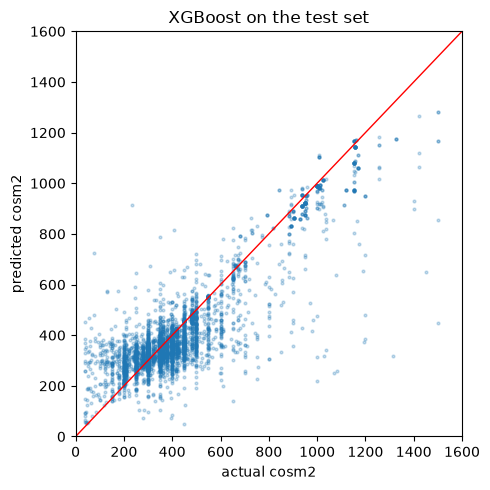

In [30]:
fig, ax = plt.subplots(figsize=(5, 5))
ax.scatter(np.expm1(y_test), np.expm1(pred_test), s=4, alpha=0.25)
lim = [0, 1600]
ax.plot(lim, lim, color="red", linewidth=1)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.set_xlabel("actual cosm2"); ax.set_ylabel("predicted cosm2")
ax.set_title(f"{DEPLOY} on the test set")
plt.tight_layout()
plt.savefig("images/pred_vs_actual.png", dpi=120)
plt.show()

### Saving the model

The whole pipeline (vectorizer + model) is saved with `pickle`. `train.py` repeats these steps as a script, and `predict.py` loads this file.

In [31]:
with open("pipeline_v1.bin", "wb") as f_out:
    pickle.dump(fitted[DEPLOY], f_out)
print("saved pipeline_v1.bin:", size_mb[DEPLOY], "MB")

saved pipeline_v1.bin: 3.0 MB


## Decisions taken

1. **Split:** plain `train_test_split` (60/20/20, `random_state=1`). Identical rows exist (section 3.3); section 5.7 checks whether they inflate the score.
2. **Tuning:** 5-fold cross-validation on train + validation for Ridge, the decision tree and XGBoost; the validation split for the random forest. The test set is never used for any choice.
3. **Rows with `cosm2 <= 50`:** kept (about 0.4% of the data). They are real values with no natural cutoff.
4. **Location:** full canton, province and region are all used. Section 5.7 shows what happens without the canton.
5. **Features:** 27 categorical + 10 numerical (section 4 lists what is excluded and why).
6. **Target:** `log1p(cosm2)`. Metrics: RMSE on that scale, RMSE in USD and R2.
7. **Model for deployment:** chosen with the rule of section 6, as a `make_pipeline(DictVectorizer(), model)` saved to `pipeline_v1.bin`.